In [ ]:
import pandas as pd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from IPython.display import display


In [89]:
base_dir = Path.cwd()
REPORTS_PATH = base_dir / "output"
SAMPLE_REPORT_PATH = REPORTS_PATH / "sample_report.csv"
SAMPLE_REPORT_PATH

PosixPath('/Users/marly389/Development/pallas/reports/output/sample_report.csv')

In [90]:
df = pd.read_csv(SAMPLE_REPORT_PATH)

df.head()

,Sample name,Dataset name,Subtype,Data silo,GEX data split,DNAm data split,Bimodal data split,RNA-seq batch
0,AML_046,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,train,NaN,NaN
1,AML_059,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,calibrate,NaN,NaN
2,AML_075,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,calibrate,NaN,NaN
3,AML_106,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,calibrate,NaN,NaN
4,SJAML030233_D1,SJC-DS-1009,"AML, APL-PML::RARA",labeled_diagnostic,train,NaN,NaN,Total


In [91]:
# Show distribution by dataset
agg = (df.groupby("Dataset name")["Dataset name"]
    .count()
    .rename("count")
    .reset_index()
)
agg

,Dataset name,count
0,Diedrich-2021,19
1,Enblad-2025,55
2,Krali-2021,142
3,Krali-2023,1338
4,Lilljebjorn-2016,195
5,SJC-DS-1009,2625
6,SJC-panALL,1988
7,Safavi-2015,4
8,Stratmann-2022,143
9,TARGET-AML,2183


In [92]:
# ── Color constants (easy to change) ──────────────────────────────────────────
COLOR_GEX     = "#CE61A6"   # blue  – GEX data split
COLOR_DNAM    = "#D46059"   # orange – DNAm data split
COLOR_BIMODAL = "#D28844"   # green  – Bimodal
COLOR_LABELED_DIAGNOSTIC = "#5C86E0"  # dark green – labeled_diagnostic
COLOR_EXCLUDED = "#EAEAEA"  # gray   – Excluded
BAR_EDGE      = "white"
BAR_WIDTH     = 0.65
FIG_BG        = "#F8F9FB"
AXES_BG       = "#FFFFFF"

# ── Aggregate ──────────────────────────────────────────────────────────────────
agg = (
    df.groupby("Dataset name")
    .agg(
        total = ("Sample name", "count"),
        n_labeled_diagnostic = (
            "Data silo",
            lambda s: (s == "labeled_diagnostic").sum(),
        ),
        n_excluded = (
            "Data silo",
            lambda s: (s != "labeled_diagnostic").sum(),
        ),
        n_gex_only = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                ~df.loc[s.index, "GEX data split"].isna() &
                df.loc[s.index, "DNAm data split"].isna()
            ),
        ),
        n_dnam_only = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                df.loc[s.index, "GEX data split"].isna() &
                ~df.loc[s.index, "DNAm data split"].isna()
            ),
        ),
        n_bimodal = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                ~df.loc[s.index, "Bimodal data split"].isna()
            ),
        ),
    )
    .sort_values("n_labeled_diagnostic", ascending=False)
    .reset_index()
)

agg


,Dataset name,total,n_labeled_diagnostic,n_excluded,n_gex_only,n_dnam_only,n_bimodal
0,SJC-panALL,1988,1662,326,1662,0,0
1,TARGET-AML,2183,1431,752,275,289,867
2,Krali-2023,1338,1136,202,71,823,241
3,SJC-DS-1009,2625,983,1642,983,0,0
4,Lilljebjorn-2016,195,174,21,174,0,0
5,Tran-2022,173,146,27,146,0,0
6,TCGA-LAML,79,79,0,2,19,58
7,Krali-2021,142,70,72,0,70,0
8,Stratmann-2022,143,41,102,2,0,39
9,Enblad-2025,55,27,28,0,26,0


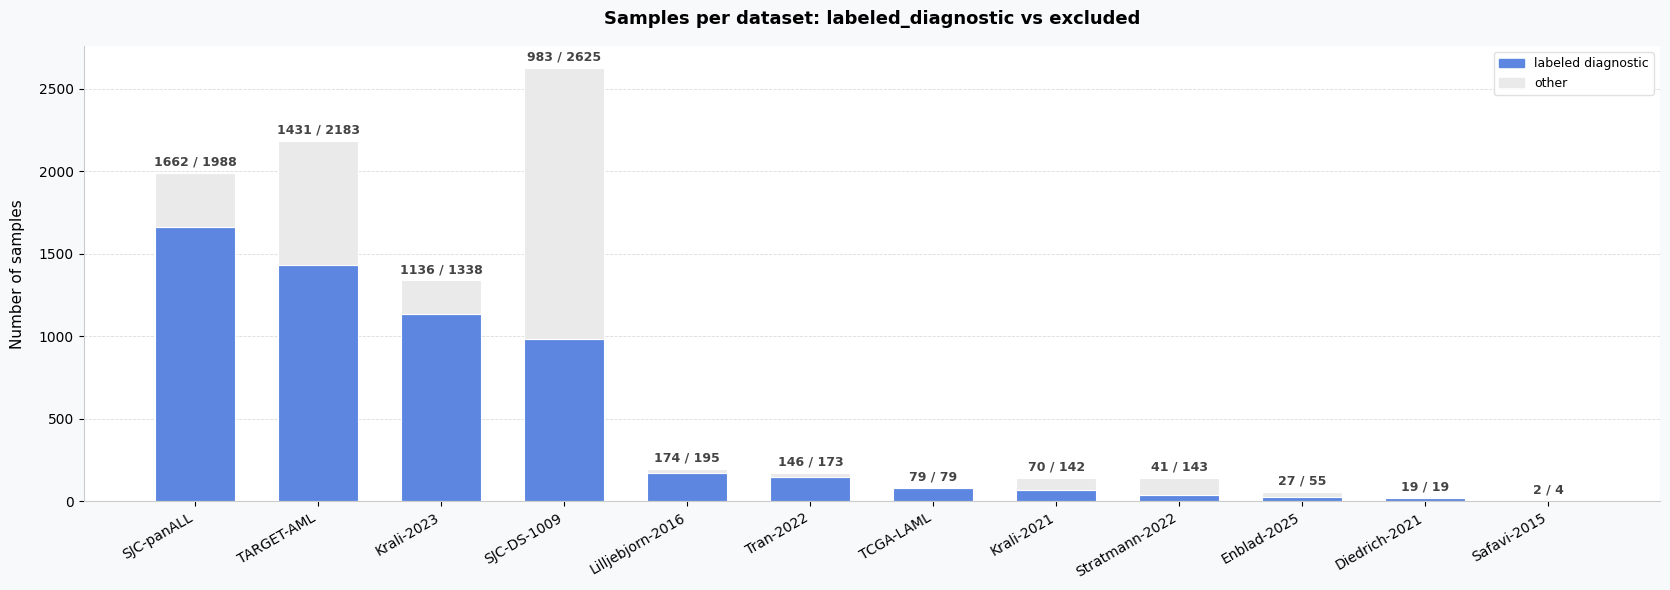

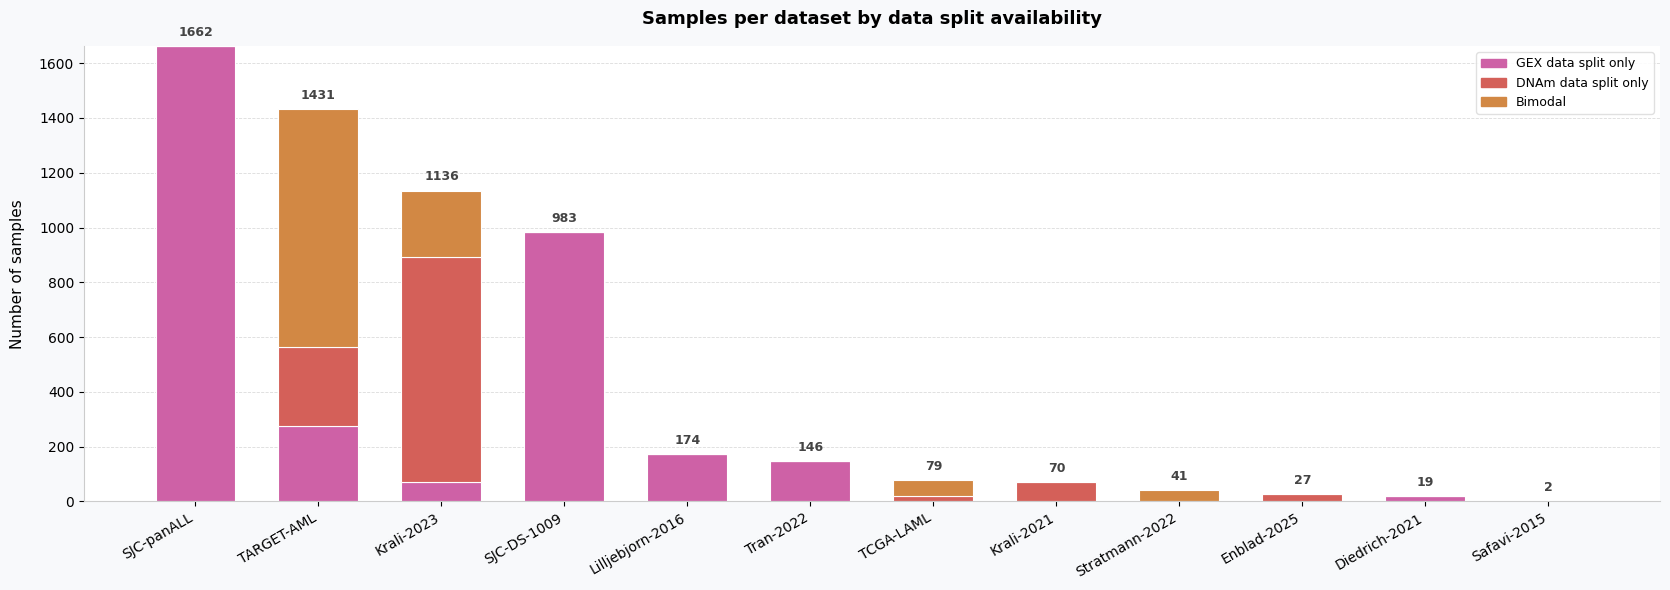

Charts saved to dataset_split_labeled_vs_excluded.png and dataset_split_barchart.png


In [ ]:
datasets_sorted = agg["Dataset name"].tolist()
x = np.arange(len(datasets_sorted))

# ── Plot 1: labeled diagnostic vs excluded ────────────────────────────────────
fig1, ax = plt.subplots(figsize=(max(8, len(datasets_sorted) * 1.4), 6))
fig1.patch.set_facecolor(FIG_BG)
ax.set_facecolor(AXES_BG)

ax.bar(
    x,
    agg["n_labeled_diagnostic"],
    width=BAR_WIDTH,
    color=COLOR_LABELED_DIAGNOSTIC,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    label="labeled_diagnostic",
)
ax.bar(
    x,
    agg["n_excluded"],
    width=BAR_WIDTH,
    color=COLOR_EXCLUDED,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg["n_labeled_diagnostic"],
    label="Excluded",
)

for i, row in agg.iterrows():
    ax.text(
        x[i], row["total"] + agg["total"].max() * 0.01,
        f'{int(row["n_labeled_diagnostic"])} / {int(row["total"])}',
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="#444444",
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets_sorted, rotation=30, ha="right", fontsize=10)
ax.set_ylabel("Number of samples", fontsize=11, labelpad=10)
ax.set_title("Samples per dataset: labeled_diagnostic vs excluded",
             fontsize=13, fontweight="bold", pad=16)
ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, color="#CCCCCC")
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

ax.legend(
    handles=[
        mpatches.Patch(color=COLOR_LABELED_DIAGNOSTIC, label="labeled diagnostic"),
        mpatches.Patch(color=COLOR_EXCLUDED, label="other"),
    ],
    loc="upper right",
    frameon=True,
    framealpha=0.9,
    edgecolor="#DDDDDD",
    fontsize=9,
)

plt.tight_layout()
plt.savefig("dataset_split_labeled_vs_excluded.png", dpi=150, bbox_inches="tight")
display(fig1)
plt.close(fig1)

# ── Plot 2: split categories without excluded samples ──────────────────────────
fig2, ax = plt.subplots(figsize=(max(8, len(datasets_sorted) * 1.4), 6))
fig2.patch.set_facecolor(FIG_BG)
ax.set_facecolor(AXES_BG)

ax.bar(
    x,
    agg["n_gex_only"],
    width=BAR_WIDTH,
    color=COLOR_GEX,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    label="GEX data split only",
)
ax.bar(
    x,
    agg["n_dnam_only"],
    width=BAR_WIDTH,
    color=COLOR_DNAM,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg["n_gex_only"],
    label="DNAm data split only",
)
ax.bar(
    x,
    agg["n_bimodal"],
    width=BAR_WIDTH,
    color=COLOR_BIMODAL,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg["n_gex_only"] + agg["n_dnam_only"],
    label="Bimodal",
)

for i, row in agg.iterrows():
    ax.text(
        x[i], row["n_labeled_diagnostic"] + agg["total"].max() * 0.01,
        str(int(row["n_labeled_diagnostic"])),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="#444444",
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets_sorted, rotation=30, ha="right", fontsize=10)
ax.set_ylabel("Number of samples", fontsize=11, labelpad=10)
ax.set_title("Samples per dataset by data split availability",
             fontsize=13, fontweight="bold", pad=16)
ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, color="#CCCCCC")
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

ax.legend(
    handles=[
        mpatches.Patch(color=COLOR_GEX, label="GEX only"),
        mpatches.Patch(color=COLOR_DNAM, label="DNAm only"),
        mpatches.Patch(color=COLOR_BIMODAL, label="Bimodal"),
    ],
    loc="upper right",
    frameon=True,
    framealpha=0.9,
    edgecolor="#DDDDDD",
    fontsize=9,
)

plt.tight_layout()
plt.savefig("dataset_split_barchart.png", dpi=150, bbox_inches="tight")
display(fig2)
plt.close(fig2)
print("Charts saved to dataset_split_labeled_vs_excluded.png and dataset_split_barchart.png")
